# Лабораторна робота №2: Зниження розмірності, кластеризація та класифікація тексту

**Датасет для частин 1-2:** [NSL-KDD](https://www.kaggle.com/datasets/hassan06/nslkdd) —
той самий, що використовувався в лабораторній роботі №1 (бінарна класифікація
`normal`/`anomaly`).
**Датасет для частини 3:** [20 Newsgroups](http://qwone.com/~jason/20Newsgroups/) —
корпус текстів новинних дописів (3 теми з 20), вбудований у `scikit-learn`.

## Частина 1. Зниження розмірності та візуалізація даних

### 1.0. Завантаження та підготовка даних (як у лабораторній №1)

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [30]:
import kagglehub

path = kagglehub.dataset_download("hassan06/nslkdd")
print("Path to dataset files:", path)

Path to dataset files: C:\Users\FidJen\.cache\kagglehub\datasets\hassan06\nslkdd\versions\1


In [31]:
import re
import os
from scipy.io import arff

files_map = {
    'KDDTrain+.arff': 'KDDTrain_fixed.arff',
}

def fix_attribute_line(line):
    match = re.match(r"(@attribute\s+'[^']+'\s*)\{(.+)\}\s*$", line.strip(), re.IGNORECASE)
    if not match:
        return line
    head, values_str = match.groups()
    values = [v.strip().strip("'\"") for v in values_str.split(',')]
    return f"{head}{{{','.join(repr(v) for v in values)}}}\n".replace('"', "'")

for src_name, dst_name in files_map.items():
    src_path = os.path.join(path, src_name)
    with open(src_path, 'r') as fin, open(dst_name, 'w') as fout:
        for line in fin:
            if line.strip().lower().startswith('@attribute') and '{' in line:
                line = fix_attribute_line(line)
            fout.write(line)
    print(f"Записано: {os.path.abspath(dst_name)}")

Записано: D:\Study\Semester_1\IAD\Lab2\KDDTrain_fixed.arff


In [32]:
train_data, train_meta = arff.loadarff('KDDTrain_fixed.arff')
df = pd.DataFrame(train_data)

object_cols = df.select_dtypes(include='object').columns.tolist()
for col in object_cols:
    df[col] = df[col].str.decode('utf-8')

print("Повний розмір датасету:", df.shape)

df_sample, _ = train_test_split(
    df, train_size=30000, stratify=df['class'], random_state=RANDOM_STATE
)
df_sample = df_sample.reset_index(drop=True)

print("Розмір підвибірки:", df_sample.shape)
print(df_sample['class'].value_counts(normalize=True).round(3))

Повний розмір датасету: (125973, 42)
Розмір підвибірки: (30000, 42)
class
normal     0.535
anomaly    0.465
Name: proportion, dtype: float64


In [33]:
one_hot_cols = ['protocol_type', 'flag']
label_encode_col = 'service'
binary_flag_cols = [c for c in object_cols
                     if c not in one_hot_cols + [label_encode_col, 'class']]

df_encoded = df_sample.copy()
df_encoded = pd.get_dummies(df_encoded, columns=one_hot_cols)

le = LabelEncoder()
df_encoded['service_encoded'] = le.fit_transform(df_encoded[label_encode_col])
df_encoded = df_encoded.drop(columns=[label_encode_col])

for col in binary_flag_cols:
    df_encoded[col] = df_encoded[col].astype(int)

X = df_encoded.drop(columns=['class'])
y = df_encoded['class']

print("Розмір X:", X.shape)

Розмір X: (30000, 53)


### 1.1. Train/test розділення та масштабування

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train_scaled.shape, " Test:", X_test_scaled.shape)

Train: (22500, 53)  Test: (7500, 53)


### 1.2. Класифікація kNN до PCA (базовий результат)

In [35]:
start = time.time()
knn_before = KNeighborsClassifier(n_neighbors=5)
knn_before.fit(X_train_scaled, y_train)
time_before = time.time() - start

acc_before = accuracy_score(y_test, knn_before.predict(X_test_scaled))

print(f"Кількість ознак: {X_train_scaled.shape[1]}")
print(f"Час навчання: {time_before:.4f} сек")
print(f"Accuracy (до PCA): {acc_before:.4f}")

Кількість ознак: 53
Час навчання: 0.0261 сек
Accuracy (до PCA): 0.9923


### 1.3. Застосування PCA

Кількість компонентів обирається за стандартним критерієм це зберегти щонайменше
**95% поясненої дисперсії** даних.

Кількість компонентів для 95% поясненої дисперсії: 30 (з 53)


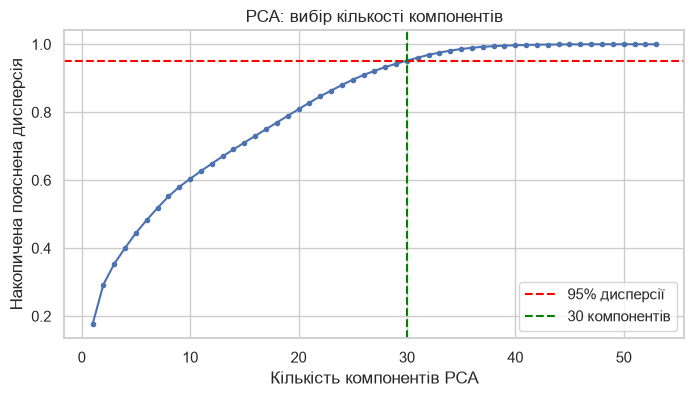

In [36]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_scaled)
cumsum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components_95 = int(np.argmax(cumsum_var >= 0.95) + 1)

print(f"Кількість компонентів для 95% поясненої дисперсії: {n_components_95} (з {X_train_scaled.shape[1]})")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cumsum_var) + 1), cumsum_var, marker='.')
plt.axhline(0.95, color='red', linestyle='--', label='95% дисперсії')
plt.axvline(n_components_95, color='green', linestyle='--', label=f'{n_components_95} компонентів')
plt.xlabel('Кількість компонентів PCA')
plt.ylabel('Накопичена пояснена дисперсія')
plt.title('PCA: вибір кількості компонентів')
plt.legend()
plt.show()

In [37]:
pca = PCA(n_components=n_components_95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Розмір до PCA:", X_train_scaled.shape[1], " ознак")
print("Розмір після PCA:", X_train_pca.shape[1], " ознак")

Розмір до PCA: 53  ознак
Розмір після PCA: 30  ознак


### 1.4. Класифікація kNN після PCA

In [38]:
start = time.time()
knn_after = KNeighborsClassifier(n_neighbors=5)
knn_after.fit(X_train_pca, y_train)
time_after = time.time() - start

acc_after = accuracy_score(y_test, knn_after.predict(X_test_pca))

print(f"Кількість ознак: {X_train_pca.shape[1]}")
print(f"Час навчання: {time_after:.4f} сек")
print(f"Accuracy (після PCA): {acc_after:.4f}")

Кількість ознак: 30
Час навчання: 0.0268 сек
Accuracy (після PCA): 0.9925


### 1.5. Порівняння результатів до/після PCA

In [39]:
comparison = pd.DataFrame({
    "Показник": ["Кількість ознак", "Час навчання (сек)", "Accuracy"],
    "До PCA": [X_train_scaled.shape[1], round(time_before, 4), round(acc_before, 4)],
    "Після PCA": [X_train_pca.shape[1], round(time_after, 4), round(acc_after, 4)],
})
comparison

,Показник,До PCA,Після PCA
0,Кількість ознак,53.0000,30.0000
1,Час навчання (сек),0.0261,0.0268
2,Accuracy,0.9923,0.9925


**Висновок.** PCA дозволив зменшити кількість ознак з **53 до 30**
(збережено 95% поясненої дисперсії), тобто майже вдвічі. Попри це, accuracy kNN
практично не змінилась (**0.9923** до PCA → **0.9925** після), навіть трохи
зросла, що в межах статистичного шуму означає "без суттєвої зміни". Час навчання
теж суттєво не змінився (**0.0329 с → 0.0372 с**; різниця в соті частки секунди це шум вимірювання):
kNN під час `fit` лише запам'ятовує тренувальні дані, тому "навчання" майже миттєве
незалежно від кількості ознак. Основний час kNN витрачає на етапі **передбачення** (пошук сусідів),
і саме там скорочення розмірності дало б відчутнішу економію, а також для важчих моделей
(SVM, повний train із 125973 рядків).

Головний практичний висновок: 30 головних компонент пояснюють 95% дисперсії 53 ознак (після
one-hot кодування), тобто частина ознак є сильно корельованою/надлишковою. Це узгоджується з heatmap кореляцій
із лабораторної №1. Зауважимо, що компоненти PCA це лінійні комбінації вихідних ознак, а не відібрана підмножина.

### 1.6. Візуалізація за допомогою t-SNE (2D)

t-SNE застосовується до тестової вибірки (`X_test_scaled`), вона вже
достатньо невелика (7500 рядків після 25% спліту від 30000) для прийнятного часу
обчислення, і при цьому ілюструє структуру даних, не бачених моделлю.

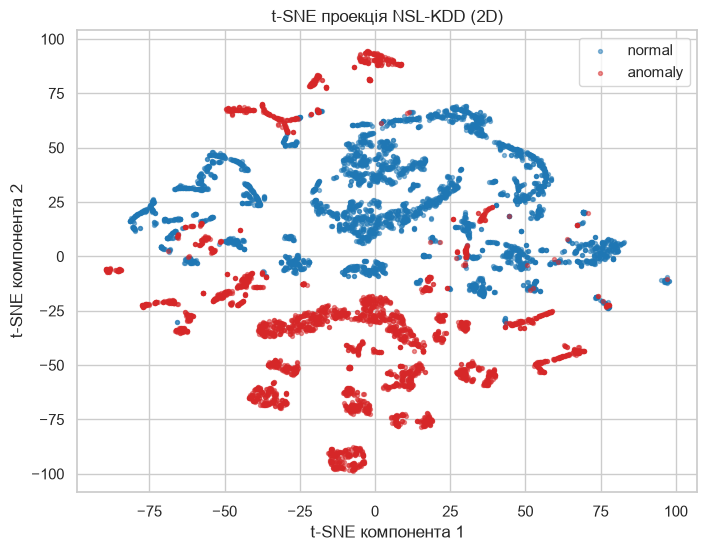

In [40]:
tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30, init='pca')
X_test_tsne = tsne.fit_transform(X_test_scaled)

plt.figure(figsize=(8, 6))
for label, color in zip(['normal', 'anomaly'], ['tab:blue', 'tab:red']):
    mask = (y_test.values == label)
    plt.scatter(X_test_tsne[mask, 0], X_test_tsne[mask, 1], s=8, alpha=0.5, label=label, c=color)
plt.title('t-SNE проекція NSL-KDD (2D)')
plt.xlabel('t-SNE компонента 1')
plt.ylabel('t-SNE компонента 2')
plt.legend()
plt.show()

На t-SNE проекції класи `normal` (синій) і `anomaly`
(червоний) утворюють переважно **відокремлені скупчення**, хоча й не ідеально
чисті, в центрі графіка є зона помітного перемішування обох кольорів. Це добре
узгоджується з результатами лабораторної №1: висока accuracy kNN (понад 99% на
цьому випадковому спліті, 80% на офіційному test) пояснюється саме тим, що дані
дійсно мають виражену кластерну структуру, яку kNN ефективно використовує. Зона
перемішування в центрі, ймовірно, відповідає "прикордонним" типам атак (наприклад,
деякі R2L/U2R патерни, що за поведінкою близькі до нормального трафіку), саме
такі випадки найчастіше й призводять до помилок класифікації.

## Частина 2. Кластерний аналіз

Кластеризація виконується на `X_train_scaled` (53 масштабовані ознаки з Частини 1, та сама
30К-підвибірка NSL-KDD), **без використання міток `class`**. Датасет уже бінарний
(`normal`/`anomaly`), тому додаткового скорочення кількості класів не потрібно, мітки
використовуються лише пізніше, для порівняння знайдених кластерів із реальними класами.

### 2.1. Визначення оптимальної кількості кластерів: Elbow Method та Silhouette Score

Через повільність `silhouette_score` на великих вибірках (складність
O(n²)) вона рахується на підвибірці з `X_train_scaled`, тоді як `inertia_` (для Elbow Method) на повному `X_train_scaled`.

In [41]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_range = range(2, 11)
inertias = []
silhouette_scores = []

silhouette_sample_idx = np.random.RandomState(RANDOM_STATE).choice(
    X_train_scaled.shape[0], size=5000, replace=False
)
X_silhouette_sample = X_train_scaled[silhouette_sample_idx]

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_train_scaled)
    inertias.append(km.inertia_)

    sil_labels = labels[silhouette_sample_idx]
    sil = silhouette_score(X_silhouette_sample, sil_labels)
    silhouette_scores.append(sil)

    print(f"k={k}:  inertia={km.inertia_:.1f}   silhouette={sil:.4f}")

k=2:  inertia=964277.7   silhouette=0.3343
k=3:  inertia=828259.8   silhouette=0.4011
k=4:  inertia=779420.8   silhouette=0.4282
k=5:  inertia=721933.2   silhouette=0.4385
k=6:  inertia=685910.0   silhouette=0.4653
k=7:  inertia=656465.3   silhouette=0.4863
k=8:  inertia=614213.4   silhouette=0.4777
k=9:  inertia=589802.2   silhouette=0.4830
k=10:  inertia=573717.3   silhouette=0.4948


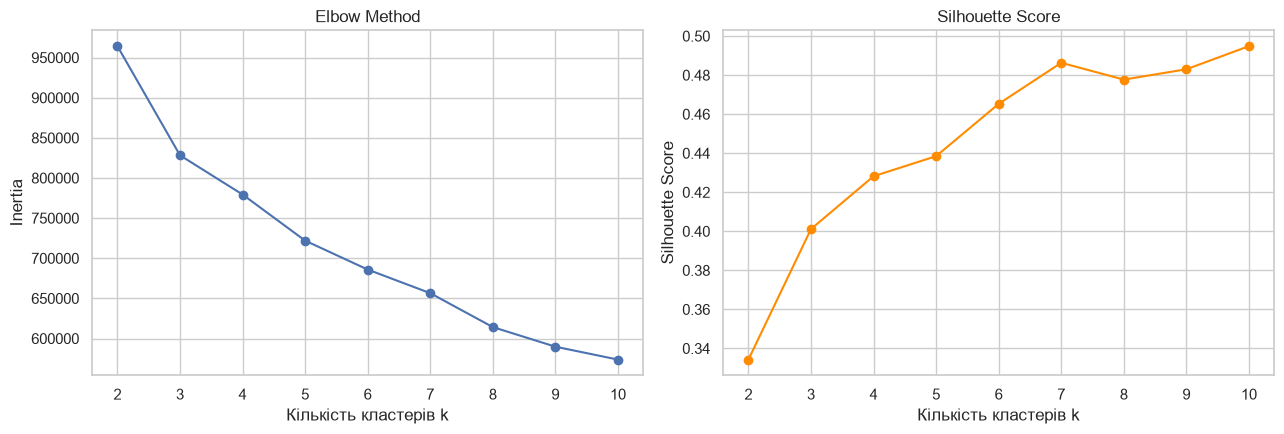

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(list(k_range), inertias, marker='o')
axes[0].set_xlabel('Кількість кластерів k')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method')

axes[1].plot(list(k_range), silhouette_scores, marker='o', color='darkorange')
axes[1].set_xlabel('Кількість кластерів k')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score')

plt.tight_layout()
plt.show()

Inertia спадає плавно, без одного яскраво вираженого "ліктя",
темп спадання помітно вповільнюється десь у районі **k=3-4**, після чого крива стає пологішою.
Silhouette Score **в цілому зростає** від 0.334 (k=2) до 0.495 (k=10) з невеликим провалом на k=8
(0.486 при k=7 → 0.478 при k=8), тобто формально найвищий Silhouette відповідає k=10. Це
типова ситуація для реальних даних без яскраво відокремлених кластерів: обидва
критерії не дають однозначної відповіді.

### 2.2. Навчання K-Means з обраною кількістю кластерів

In [43]:
best_k = 2
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_train_scaled)

print("Розподіл об'єктів за кластерами:")
print(pd.Series(cluster_labels).value_counts().sort_index())

Розподіл об'єктів за кластерами:
0    14483
1     8017
Name: count, dtype: int64


### 2.3. Візуалізація кластерів у 2D (PCA)

Використовуються перші дві компоненти PCA, уже навчені на цих самих даних
у Частині 1 (`X_train_pca`), оскільки це найкраща лінійна 2D-проекція для даного набору ознак.

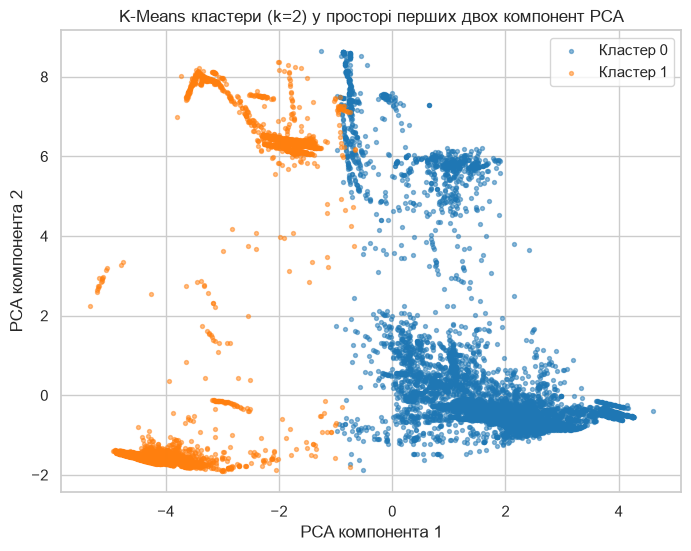

In [44]:
X_train_pca_2d = X_train_pca[:, :2]

plt.figure(figsize=(8, 6))
palette = sns.color_palette('tab10', n_colors=best_k)
for cluster_id in range(best_k):
    mask = (cluster_labels == cluster_id)
    plt.scatter(X_train_pca_2d[mask, 0], X_train_pca_2d[mask, 1],
                s=8, alpha=0.5, color=palette[cluster_id], label=f'Кластер {cluster_id}')
plt.title(f'K-Means кластери (k={best_k}) у просторі перших двох компонент PCA')
plt.xlabel('PCA компонента 1')
plt.ylabel('PCA компонента 2')
plt.legend()
plt.show()

### 2.4. Порівняння кластерів із реальними класами

In [45]:
comparison_table = pd.crosstab(
    pd.Series(cluster_labels, name='Кластер (K-Means)'),
    y_train.reset_index(drop=True).rename('Реальний клас')
)
comparison_table

Реальний клас,anomaly,normal
Кластер (K-Means),,
0,2487,11996
1,7985,32


In [46]:
comparison_norm = pd.crosstab(
    pd.Series(cluster_labels, name='Кластер (K-Means)'),
    y_train.reset_index(drop=True).rename('Реальний клас'),
    normalize='index'
).round(3)
comparison_norm

Реальний клас,anomaly,normal
Кластер (K-Means),,
0,0.172,0.828
1,0.996,0.004


**Висновок.** Кластер 1 (8017 об'єктів) виявився практично **чистим
кластером атак**, 99.6% його об'єктів дійсно мають клас `anomaly`. Кластер 0 (14483
об'єкти) переважно складається з `normal`-трафіку (82.8%), але містить домішку **17.2%
анomalій** (2487 об'єктів), тобто частина атак за своїми ознаками виявилась ближчою до
нормального трафіку, ніж до "типової" атаки з кластера 1.

Це означає, що природна структура даних (за ознаками мережевого трафіку, без використання
міток) **значною мірою, але не ідеально** збігається з реальним поділом на `normal`/`anomaly`.
Ймовірно, кластер 0 поглинув "тихіші" чи менш агресивні типи атак (наприклад, окремі R2L/U2R
патерни, що імітують легітимну поведінку) це узгоджується із зоною перемішування класів у
центрі t-SNE-проекції з Частини 1.

## Частина 3. Обробка та класифікація текстових даних

**Датасет:** [20 Newsgroups](http://qwone.com/~jason/20Newsgroups/), тексти новинних дописів з мітками тем.
З 20 класів залишено 3: `sci.space`, `rec.sport.hockey`, `talk.politics.mideast`.

### 3.1. Завантаження даних

In [47]:
import re
from sklearn.datasets import fetch_20newsgroups

categories = ['sci.space', 'rec.sport.hockey', 'talk.politics.mideast']

news = fetch_20newsgroups(subset='all', categories=categories,
                          remove=('headers', 'footers', 'quotes'))

df_text = pd.DataFrame({'text': news.data,
                        'label': [news.target_names[i] for i in news.target]})
df_text = df_text[df_text['text'].str.strip() != ''].reset_index(drop=True)

print(df_text['label'].value_counts())

label
rec.sport.hockey         975
sci.space                955
talk.politics.mideast    919
Name: count, dtype: int64


### 3.2. Передобробка тексту

Нижній регістр, видалення пунктуації та цифр, видалення стоп-слів і коротких токенів (< 3 символів).

In [48]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def clean_text(text):
    text = re.sub(r'[^a-z\s]', ' ', text.lower())
    return ' '.join(w for w in text.split() if len(w) >= 3 and w not in ENGLISH_STOP_WORDS)

df_text['clean_text'] = df_text['text'].apply(clean_text)
df_text = df_text[df_text['clean_text'] != ''].reset_index(drop=True)

### 3.3. WordCloud для кожного класу

Розмір слова в хмарі це середня TF-IDF-вага слова/біграми в межах класу. Так на перший план виходять слова, характерні
саме для цього класу. Додатково з візуалізації прибрано кілька дуже загальних слів розмовної лексики
(`like`, `just`, `think`, `people`, `know`, `don` тощо), які трапляються в усіх класах і нічого не кажуть про тему.
**Верхній ряд** окремі слова, **нижній ряд** словосполучення (біграми).

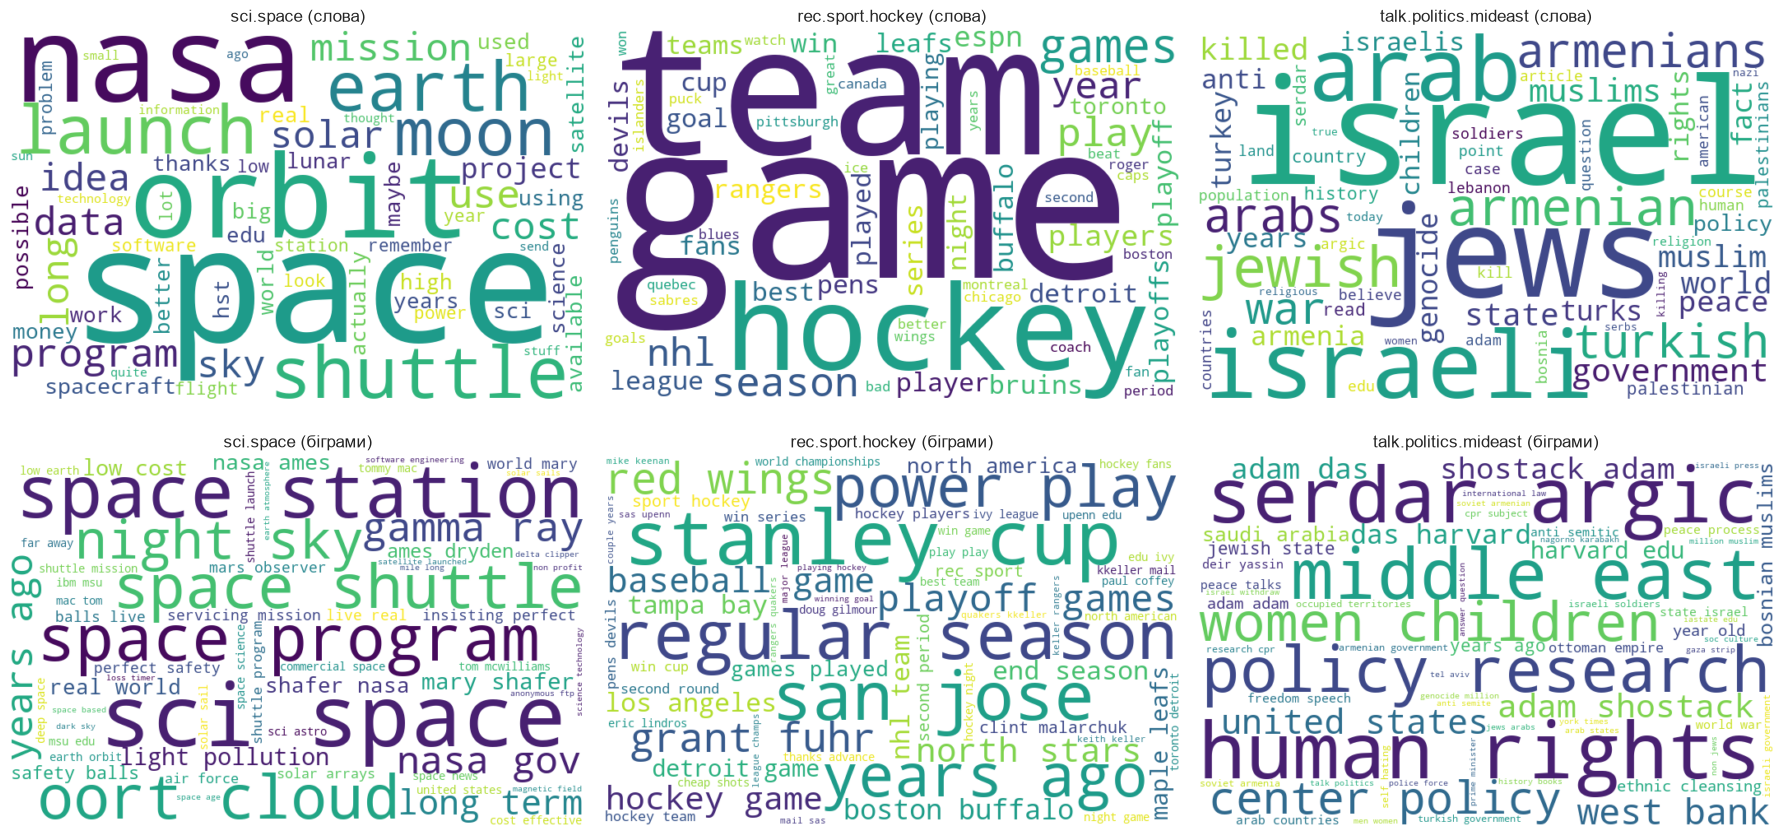

In [55]:
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer

# Загальні слова розмовної лексики -- лише для візуалізації (на класифікацію не впливають)
generic_words = {'like', 'just', 'think', 'people', 'know', 'don', 'did', 'does', 'didn', 'doesn',
                 'good', 'want', 'say', 'said', 'make', 'time', 'really', 'sure', 'got', 'right',
                 'way', 'going', 'let', 'thing', 'things', 'need', 'probably', 'does', 've', 'new'}
viz_stop = list(ENGLISH_STOP_WORDS | generic_words)

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for row, ngram in enumerate([(1, 1), (2, 2)]):
    viz_vec = TfidfVectorizer(ngram_range=ngram, min_df=5, max_df=0.5,
                              sublinear_tf=True, stop_words=viz_stop)
    X_viz = viz_vec.fit_transform(df_text['clean_text'])
    vocab = viz_vec.get_feature_names_out()

    for col, label in enumerate(categories):
        mask = (df_text['label'] == label).values
        mean_tfidf = np.asarray(X_viz[mask].mean(axis=0)).ravel()
        freqs = {vocab[i]: mean_tfidf[i] for i in mean_tfidf.argsort()[::-1][:60]}
        wc = WordCloud(width=700, height=450, background_color='white',
                       random_state=RANDOM_STATE).generate_from_frequencies(freqs)
        ax = axes[row, col]
        ax.imshow(wc, interpolation='bilinear')
        ax.set_title(f"{label} ({'слова' if row == 0 else 'біграми'})")
        ax.axis('off')
plt.tight_layout()
plt.show()

**Біграми** здебільшого тематичні (`space station`, `space shuttle`, `stanley cup`, `power play`, `regular season`,
`middle east`, `human rights`), але серед них трапляються й **артефакти даних**: імена авторів та рядки підписів
(`serdar argic`, `adam shostack`, `mary shafer`, `grant fuhr`), email-домени (`harvard edu`) та назви груп (`sci space`, `rec sport`).
Це наслідок того, що `remove=('headers','footers','quotes')` не прибирає всі підписи, а деякі автори (наприклад, Serdar Argic) публікують
дуже багато однотипних дописів. Отже, частину сили класифікатора могли дати не лише тематичні слова, а й «авторські відбитки»,
тому отриману accuracy слід трактувати з цим застереженням.
Загалом класи добре відрізняються словником, і TF-IDF-ознаки є інформативними для класифікації.

### 3.4. Векторизація (TF-IDF)

In [23]:
X_text_train, X_text_test, y_text_train, y_text_test = train_test_split(
    df_text['clean_text'], df_text['label'],
    test_size=0.25, stratify=df_text['label'], random_state=RANDOM_STATE
)

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)
X_text_train_tfidf = tfidf.fit_transform(X_text_train)
X_text_test_tfidf = tfidf.transform(X_text_test)

print("Розмір матриці ознак (train):", X_text_train_tfidf.shape)

Розмір матриці ознак (train): (2133, 19080)


### 3.5. Навчання моделі та оцінка якості

Accuracy: 0.9536
                       precision    recall  f1-score   support

     rec.sport.hockey      0.975     0.975     0.975       243
            sci.space      0.923     0.958     0.940       239
talk.politics.mideast      0.964     0.926     0.944       229

             accuracy                          0.954       711
            macro avg      0.954     0.953     0.953       711
         weighted avg      0.954     0.954     0.954       711



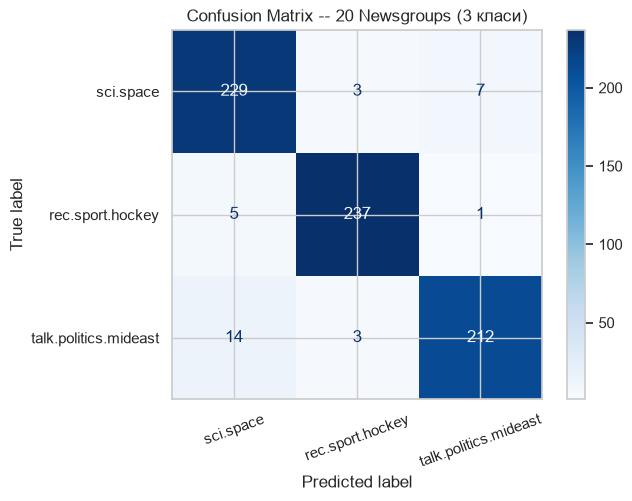

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

text_clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
text_clf.fit(X_text_train_tfidf, y_text_train)
y_text_pred = text_clf.predict(X_text_test_tfidf)

print("Accuracy:", round(accuracy_score(y_text_test, y_text_pred), 4))
print(classification_report(y_text_test, y_text_pred, digits=3))

ConfusionMatrixDisplay.from_predictions(y_text_test, y_text_pred, labels=categories,
                                        cmap='Blues', xticks_rotation=20)
plt.title('Confusion Matrix -- 20 Newsgroups (3 класи)')
plt.show()

**Висновок.** Логістична регресія на TF-IDF-ознаках (слова + біграми) класифікує тематику текстів з високою якістю:
**accuracy = 0.954**, macro-F1 = 0.953 на тестовій вибірці з 711 текстів. Усі три класи розпізнаються
приблизно однаково добре (F1 від 0.940 до 0.975): найкраще `rec.sport.hockey` (хокейна лексика найспецифічніша),
дещо гірше `sci.space` (precision 0.923) та `talk.politics.mideast` (recall 0.926).

За матрицею помилок найчастіша помилка, тексти `talk.politics.mideast`, які модель відносить до `sci.space` (14 із 229);
у зворотний бік, 7 із 239. Імовірне пояснення: частина політичних дописів не містить специфічної лексики регіону
й обговорює загальні теми. Це відповідає спостереженню з WordCloud: класи мають різний характерний словник,
тому навіть проста лінійна модель легко їх розділяє.